<a href="https://colab.research.google.com/github/freddyjosephthanikkal/Deep_Learning/blob/main/RGB_image_classifier_Handbag_and_Shoes_Data_Augmentation_and_Transfer_Learning_(Resnet).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [64]:
!!pip install -q git+https://github.com/keras-team/keras-hub.git
!!pip install -q --upgrade keras

[]

* ! -> execute a shell command
* !! -> execute a shell command and capture its output as a list of lines
* package manager / library
* -q -> install quietly -> no notifications
* Upgrade to Keras 3

In [65]:
import os
import json
import math
import numpy as np
import matplotlib.pyplot as plt

import keras
from keras import losses
from keras import ops
from keras import optimizers
from keras.optimizers import schedules
from keras import metrics
from keras.applications.imagenet_utils import decode_predictions
import keras_hub

import tensorflow as tf
import tensorflow_datasets as tfds

* os -> helps python to interact with th operating system -> the files in the computer
* json -> JavaScript Object Notation -> stores structured information
* math -> standard math library
* losses -> calculate the model loss
* ops -> operation -> mathamatical and tensor operations
* optimizers -> update the weights and biases -> like sgd, adam, RMSprop
* schedules -> uses the optimizer's configured learning rate throughout training unless changed.
* metrics -> show the metrics data like precision, accuracy, etc
* decode_predictions -> convert the numerical predictions to human readable labels.
* keras_hub -> pretrained neural network components and architectures.
* tensorflow_datasets -> It provides features such as:
      - Downloading and preparing datasets.
      - Splitting datasets into training and testing portions.
      - Loading data in batches.
      - Shuffling examples.
      - Building input pipelines

In [66]:
from tensorflow import keras
from keras.layers import Dropout, Dense, GlobalAveragePooling1D, Flatten
import keras_hub
from keras import layers
from keras.layers import Lambda
import pandas as pd
import matplotlib.pyplot as plt
keras.utils.set_random_seed(42)

* Dropout -> technique to reduce overfitting -> it randomly disables a fraction of outputs during training.
* Dense -> fully connected layers
* GlobalAveragePooling -> takes input matrix, averages its rows -> so a matrix of size 4*3 becomes 1*3
* Flatten -> Rearrange the matrix to a long vector -> (6,6,32) -> (1152)
* Keras_hub -> provides pretrained models and components -> Instead of training a CNN from scratch, start with a model that has already learned useful visual features from a large dataset -> Transfer Learning
* Layers -> Imports keras layers -> eg -> layers.dense(256) -> same as from keras.layers import Dropout, Dense, GlobalAveragePooling1D, Flatten
* Lambda -> Turn a custom mathematical operation to a keras layer.


In [67]:
!wget -q -P ./ https://www.dropbox.com/s/w07liww46kgxo1m/handbags-shoes.zip
!unzip -qq handbags-shoes.zip

replace handbags-shoes/.DS_Store? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


* ! ->	Runs a shell command from a Colab notebook cell.
* wget ->	Downloads a file from a URL.
* -q ->	Quiet mode; suppresses download progress and most messages.
* -P ./ ->	Saves the downloaded file in the current directory.
* URL	-> The location of the ZIP file.
* unzip ->	Extracts ZIP archives.
* -qq	-> Extra-quiet mode; suppresses extraction messages.
* handbags-shoes.zip	-> The archive to extract.

In [68]:
import os, shutil, pathlib
base_dir = pathlib.Path("/content/handbags-shoes")

* shutil -> shell utility -> high level file operations
* pathlib -> working with file paths
* base_dir -> the extracted content path is stored in a variable named base_dir

In [69]:
for category in ('handbags', 'shoes'):
  fnames = os.listdir(base_dir/category)

  dir = base_dir /'train' / category
  os.makedirs(dir, exist_ok=True)
  for fname in fnames[:50]:
      shutil.copyfile(src=base_dir/category/fname,dst=dir/fname)

  dir = base_dir /'validation' / category
  os.makedirs(dir, exist_ok=True)
  for fname in fnames[50:75]:
      shutil.copyfile(src=base_dir/category/fname,dst=dir/fname)

  dir = base_dir /'test' / category
  os.makedirs(dir, exist_ok=True)
  for fname in fnames[75:]:
      shutil.copyfile(src=base_dir/category/fname,dst=dir/fname)

* for loop -> runs twice -> create directory for shoes and handbag.
* 2 folders -> containing separate training, validation and test folders
* fnames[] -> fixed split based on the order returned by os.listdir()
           -> Does not randomly shuffle the images before split!
* exist_ok=True -> Check if the directories already exixts

In [70]:
train_dataset = keras.utils.image_dataset_from_directory(
    base_dir / 'train',
    image_size=(224, 224),
    batch_size=32)

validation_dataset = keras.utils.image_dataset_from_directory(
    base_dir / 'validation',
    image_size=(224, 224),
    batch_size=32)

test_dataset = keras.utils.image_dataset_from_directory(
    base_dir / 'test',
    image_size=(224, 224),
    batch_size=32)


Found 99 files belonging to 2 classes.
Found 48 files belonging to 2 classes.
Found 38 files belonging to 2 classes.


* creating datasets from the previously arranged folders for training, testing and validation.
* all images are resized to 244*244 pixels.
* keras also makes batches of 32 images and corresponding labels.
* Convert the images to tensors.

In [71]:
for images, _ in train_dataset.take(1):
  print(images[0].shape)

(224, 224, 3)


* Each image is 244*244 and has RGB channels -> so (244,244,3)

In [72]:
num_classes = 2
def preprocess_data(image, label):
    label = tf.one_hot(label, num_classes)
    return image, label

train_dataset = train_dataset.map(preprocess_data)
validation_dataset = validation_dataset.map(preprocess_data)
test_dataset = test_dataset.map(preprocess_data)
for images, labels in train_dataset.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Image shape: (32, 224, 224, 3)
Label shape: (32, 2)


* num_classes =2 -> tells keras there are 2 possible classes
* function - preprocess_data -> accept arguments -> image and label
* on_hot -> converts the integer into vector whose length equals number of classes -> let handbag = 0 -> it becomes [1,0] and Let shoe = 1 -> it becomes [0,1]
* shape of label changes from (32,) to (32,2)
* return image, label -> return the image and new label
* train_dataset.map(preprocess_data) -> map -> applies the updated labels to every element in train_dataset
* same for all the datasets
* image shape -> (32*244*244*3)
* label shape -> (32*2)

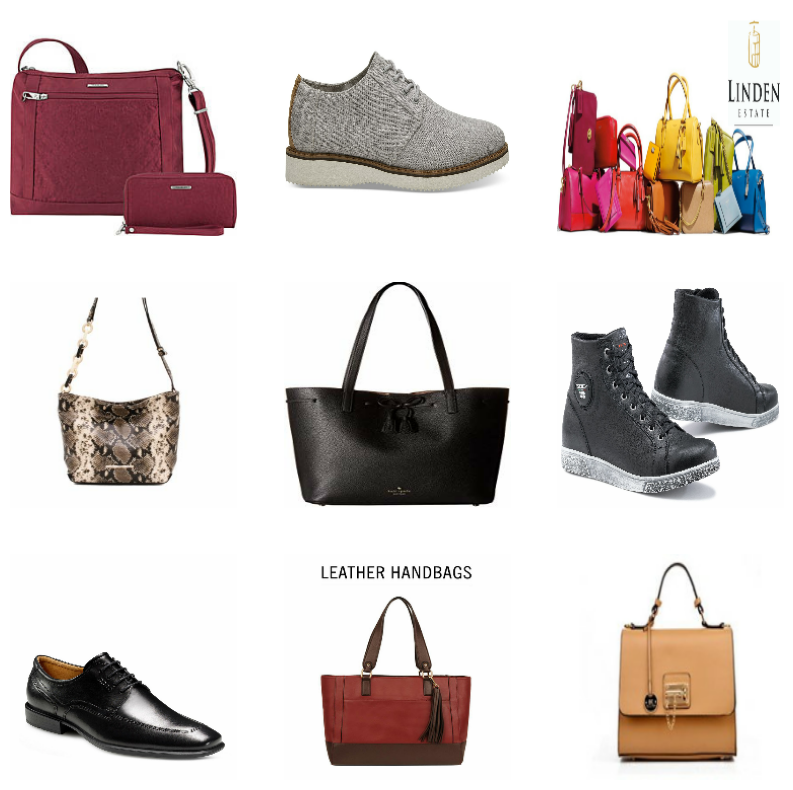

In [73]:
plt.figure(figsize=(10, 10))
for images, _ in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.axis("off")

* Display 9 sample image from the training dataset in a 3*3 grid
* 10*10 inch canvas
* for images, _ in train_dataset.take(1): takes the first batch in the train_dataset
* it has both images and labels -> we use a "_" to exclude using the labels.
* (3, 3, i + 1) -> (rows, columns, position)
* imshow -> can display the numpy arrays as images!
* .astype("uint8") -> convert to unsigned int 8 bit

In [74]:
def augment_data(image):
  x = keras.layers.RandomFlip("horizontal")(image)
  x = keras.layers.RandomRotation(0.1)(x)
  x = keras.layers.RandomZoom(0.2)(x)
  return x

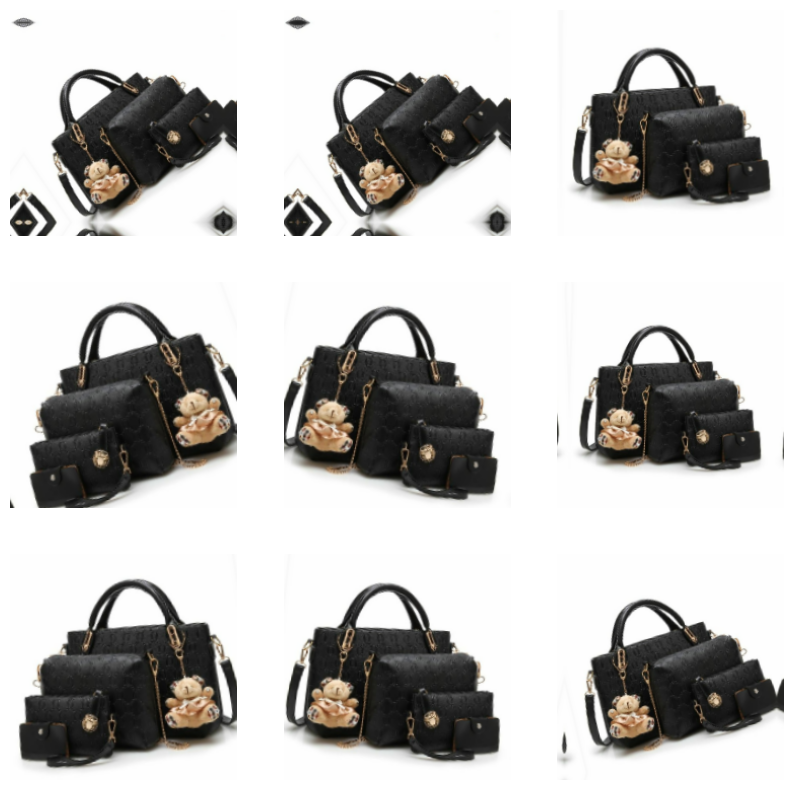

In [75]:
plt.figure(figsize=(10, 10))
for images, _ in train_dataset.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = augment_data(images[0])
    plt.imshow(augmented_image.numpy().astype("uint8"))
    plt.axis("off")

In [76]:
input = keras.Input(shape=(224,224,3))

# we insert the data augmentation layers here
h = keras.layers.RandomFlip("horizontal")(input)
h = keras.layers.RandomRotation(0.1)(h)
h = keras.layers.RandomZoom(0.2)(h)

# rest of the model is the same as before

h = keras.layers.Rescaling(1./255)(h)


# first convolutional block
h = keras.layers.Conv2D(32,                    # the number of filters
                        kernel_size=(2, 2),    # the shape of each filter
                        activation="relu",
                        name="Conv_1")(h)
h = keras.layers.MaxPool2D()(h)


# second convolutional block
h = keras.layers.Conv2D(32,                    # the number of filters
                        kernel_size=(2, 2),    # the shape of each filter
                        activation="relu",
                        name="Conv_2")(h)
h = keras.layers.MaxPool2D()(h)

# flatten layer
h = keras.layers.Flatten()(h)

# output layer
output = keras.layers.Dense(2, activation="softmax")(h)

model = keras.Model(input, output)

In [77]:
model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_23 (RandomFlip)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_23              │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_23 (RandomZoom)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_1 (Conv2D)                 │ (None, 223, 223, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv2D)                 │ (None, 110, 110, 32)   │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 55, 55, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 96800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 2)              │       193,602 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 198,146 (774.01 KB)

 Trainable params: 198,146 (774.01 KB)

 Non-trainable params: 0 (0.00 B)

In [78]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [79]:
history = model.fit(train_dataset,
                    epochs=10,
                    validation_data=validation_dataset)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 406ms/step - accuracy: 0.5051 - loss: 4.1762 - val_accuracy: 0.5208 - val_loss: 4.0214
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 341ms/step - accuracy: 0.5051 - loss: 3.4723 - val_accuracy: 0.4792 - val_loss: 1.1336
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 313ms/step - accuracy: 0.4949 - loss: 1.8959 - val_accuracy: 0.4792 - val_loss: 1.5801
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - accuracy: 0.5556 - loss: 1.0781 - val_accuracy: 0.5208 - val_loss: 0.7718
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 208ms/step - accuracy: 0.5051 - loss: 0.8645 - val_accuracy: 0.5208 - val_loss: 0.8599
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 199ms/step - accuracy: 0.5051 - loss: 0.7440 - val_accuracy: 0.7500 - val_loss: 0.5661
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 187ms/step - accuracy: 0.5859 - loss: 0.6556 - val_accuracy: 0.6250 - val_loss: 0.5950
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 208ms/step - accuracy: 0.6465 - loss: 0.6138 - val_accuracy: 0.8750 - val_loss:

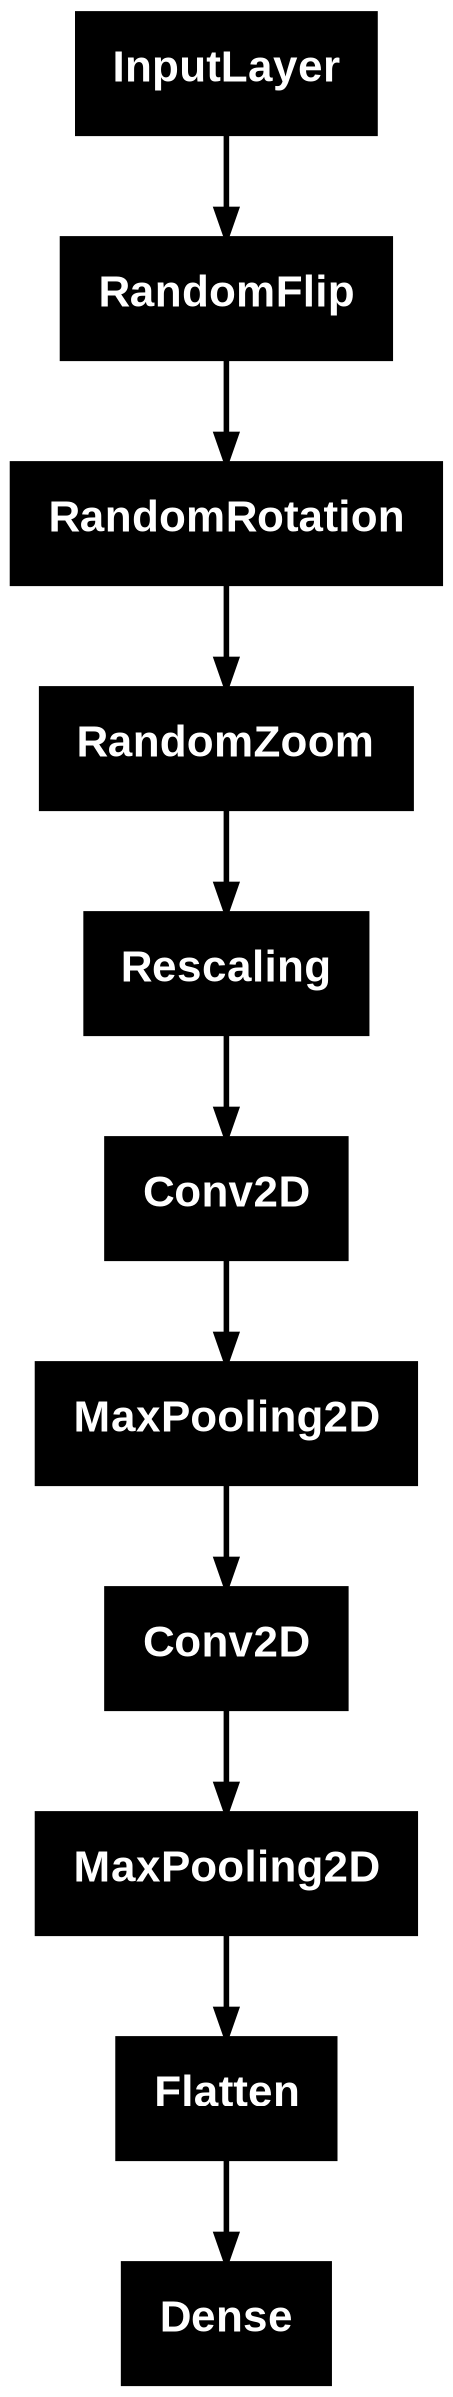

In [80]:
keras.utils.plot_model(model)

In [81]:
def plot_loss_curves(history):
  plt.clf()
  history_dict = history.history
  loss_values = history_dict["loss"]
  val_loss_values = history_dict["val_loss"]
  epochs = range(1, len(loss_values) + 1)
  plt.plot(epochs, loss_values, "bo", label="Training loss")
  plt.plot(epochs, val_loss_values, "b", label="Validation loss")
  plt.title("Training and validation loss")
  plt.xlabel("Epochs")
  plt.ylabel("Loss")
  plt.legend()
  plt.show()

def plot_acc_curves(history):
  plt.clf()
  history_dict = history.history
  acc = history_dict["accuracy"]
  val_acc = history_dict["val_accuracy"]
  epochs = range(1, len(acc) + 1)
  plt.plot(epochs, acc, "bo", label="Training acc")
  plt.plot(epochs, val_acc, "b", label="Validation acc")
  plt.title("Training and validation accuracy")
  plt.xlabel("Epochs")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.show()

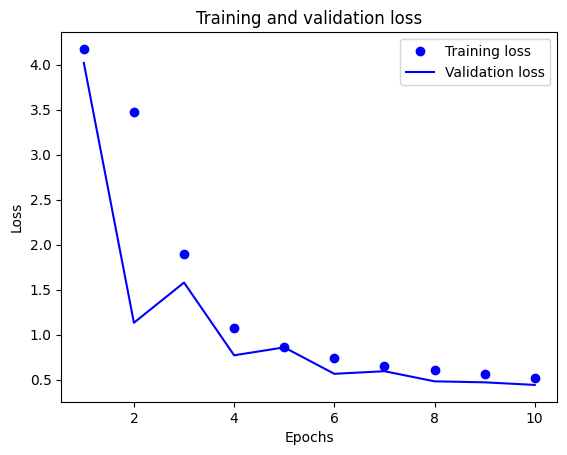

In [82]:
plot_loss_curves(history)

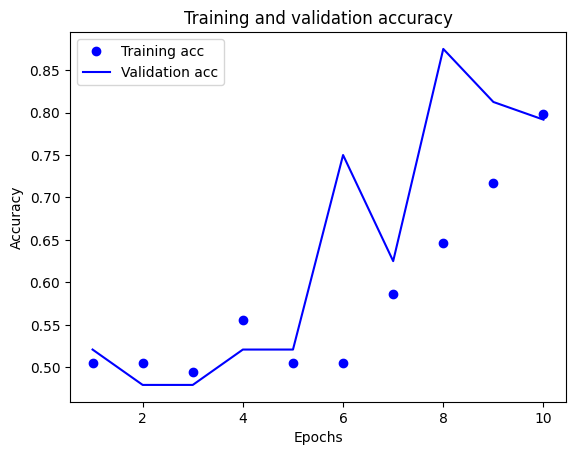

In [83]:
plot_acc_curves(history)

In [84]:
model.evaluate(test_dataset)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.7895 - loss: 0.4692


[0.4691894054412842, 0.7894737124443054]

### **Model built with Transfer Learning**

work with ResNet-50 (rather than ResNet-34 as shown in the picture below) since it comes pre-packaged with Keras.

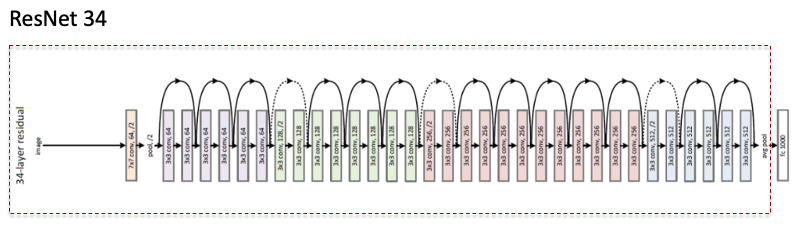

In [85]:
resnet50_base = keras.applications.ResNet50(
  weights='imagenet',
  include_top=False,
  input_shape=(224, 224, 3))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [86]:
resnet50_base.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_11      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_11[0… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 23,534,592 (89.78 MB)

 Non-trainable params: 53,120 (207.50 KB)



In [87]:
keras.utils.plot_model(resnet50_base)

Next, we run our dataset through "headless ResNet" to get the transformed, "smart" inputs.


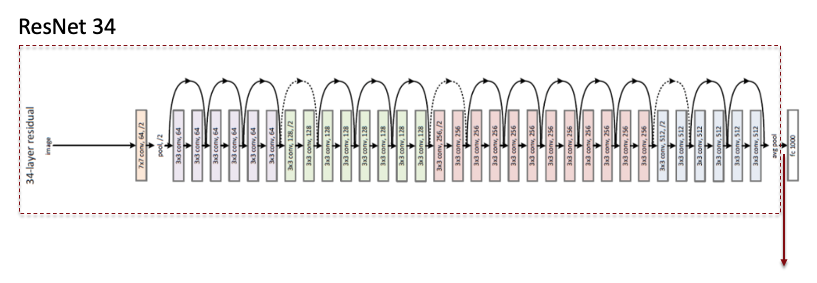

In [88]:
def get_features_and_labels(dataset):
  all_features = []
  all_labels = []
  for images, labels in dataset:
    preprocessed_images = keras.applications.resnet50.preprocess_input(images)
    features = resnet50_base.predict(preprocessed_images)
    all_features.append(features)
    all_labels.append(labels)
  return np.concatenate(all_features), np.concatenate(all_labels)

In [89]:
train_features, train_labels =  get_features_and_labels(train_dataset)
val_features, val_labels =  get_features_and_labels(validation_dataset)
test_features, test_labels =  get_features_and_labels(test_dataset)

1/1 ━━━━━━━━━━━━━━━━━━━━ 16s 16s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step


In [90]:
train_features.shape

(99, 7, 7, 2048)

In [95]:
input = keras.Input(shape=(7, 7, 2048))
h = keras.layers.Flatten()(input)
h = keras.layers.Dense(256, activation="relu")(h)
h = keras.layers.Dropout(0.5)(h)

# Change this layer to 2 outputs with softmax
output = keras.layers.Dense(2, activation="softmax")(h)

model = keras.Model(input, output)

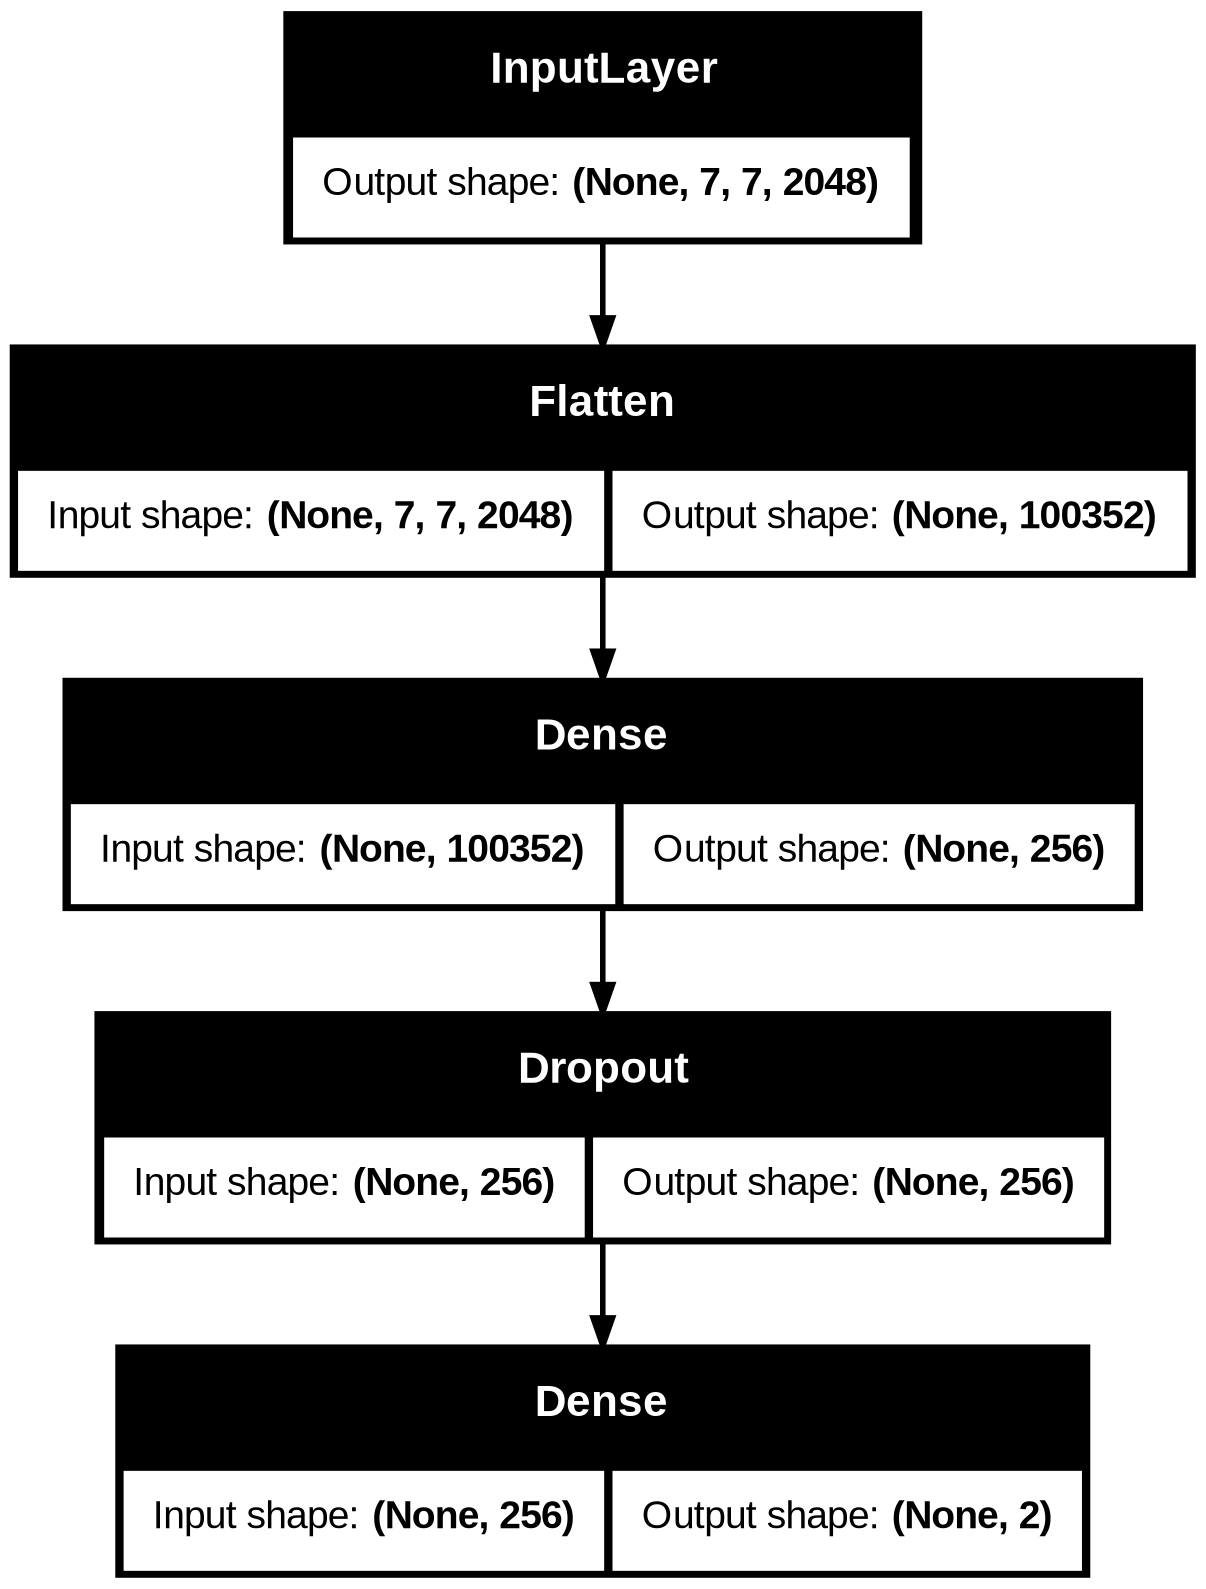

In [96]:
keras.utils.plot_model(model, show_shapes=True)

In [97]:
model.summary()

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 7, 7, 2048)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_47 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,690,882 (98.00 MB)

 Trainable params: 25,690,882 (98.00 MB)

 Non-trainable params: 0 (0.00 B)

In [98]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

history = model.fit(train_features,
                    train_labels,
                    epochs=20,
                    validation_data=(val_features, val_labels))

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 881ms/step - accuracy: 0.6364 - loss: 23.4329 - val_accuracy: 0.8125 - val_loss: 14.7309
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8889 - loss: 6.8749 - val_accuracy: 0.9792 - val_loss: 0.5437
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 8.8022e-06
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 0.9792 - val_loss: 1.3080
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9899 - loss: 1.4621 - val_accuracy: 0.9792 - val_loss: 1.9405
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9899 - loss: 0.3820 - val_accuracy: 0.9792 - val_loss: 0.5607
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9798 - loss: 0.5228 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0

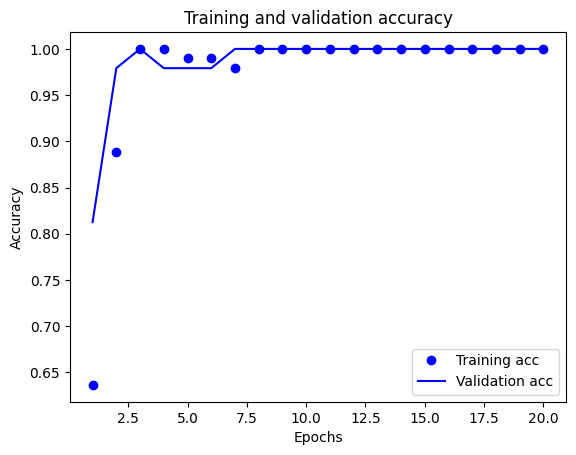

In [99]:
plot_acc_curves(history)

In [100]:
model.evaluate(test_features, test_labels)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 746ms/step - accuracy: 1.0000 - loss: 0.0000e+00


[0.0, 1.0]

In [101]:
# Camera Capture code snippet courtesy Google Colab


from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename


In [108]:
def predict_image(im):

    img = keras.utils.load_img(im, target_size=(224, 224))
    arr = keras.utils.img_to_array(img)

    # Same preprocessing used during ResNet training
    arr = keras.applications.resnet50.preprocess_input(arr)
    arr = np.expand_dims(arr, axis=0)

    # Extract ResNet features
    features = resnet50_base.predict(arr, verbose=0)

    # Classify the features
    probabilities = model.predict(features, verbose=0)[0]

    class_names = ["HANDBAG", "SHOE"]

    predicted_index = np.argmax(probabilities)

    print("Prediction:", class_names[predicted_index])
    print("Confidence:", f"{probabilities[predicted_index]:.2%}")
    print("Handbag probability:", f"{probabilities[0]:.2%}")
    print("Shoe probability:", f"{probabilities[1]:.2%}")

<IPython.core.display.Javascript object>

Saved to photo.jpg


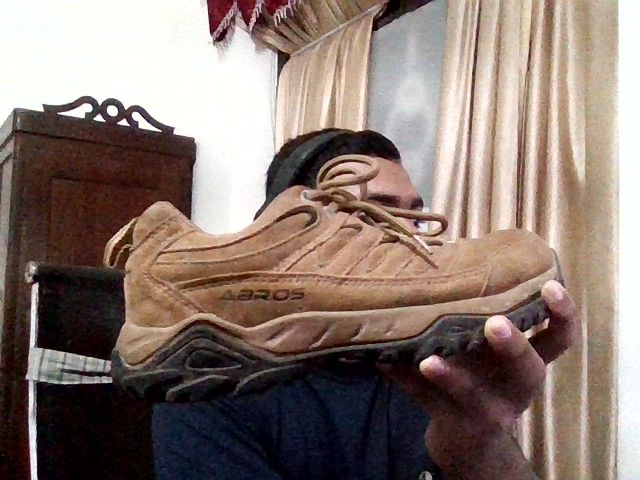

Prediction: SHOE
Confidence: 100.00%
Handbag probability: 0.00%
Shoe probability: 100.00%


In [109]:
# Camera Capture code snippet courtesy Google Colab

from IPython.display import Image
try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
  predict_image(filename)
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))